Apply bias mitigation techniques if necessary by implementing reweighting, adversarial debiasing, or preprocessing corrections, testing multiple bias-removal strategies and quantifying their effects on both fairness and performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"
group_column = "sex"  # Change to your actual demographic column

if group_column not in df.columns:
    raise ValueError(f"Demographic column '{group_column}' not found.")

df = df.dropna(subset=features + [target, group_column]).copy()

X = df[features]
y = df[target].astype(int)
groups = df[group_column]

X_train, X_temp, y_train, y_temp, g_train, g_temp = train_test_split(
    X, y, groups, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test, g_val, g_test = train_test_split(
    X_temp, y_temp, g_temp, test_size=0.5,
    random_state=42, stratify=y_temp
)

def create_model():
    return make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42
        )
    )

baseline = create_model()
baseline.fit(X_train, y_train)

print("Baseline model trained.")

Baseline model trained.


In [2]:
train_meta = pd.DataFrame({
    "group": g_train,
    "target": y_train
})

group_prob = train_meta["group"].map(
    train_meta["group"].value_counts(normalize=True)
)

target_prob = train_meta["target"].map(
    train_meta["target"].value_counts(normalize=True)
)

joint_prob = train_meta.groupby(
    ["group", "target"]
)["target"].transform("count") / len(train_meta)

sample_weights = (group_prob * target_prob / joint_prob).to_numpy()

reweighted = create_model()

reweighted.fit(
    X_train,
    y_train,
    randomforestclassifier__sample_weight=sample_weights
)

print("Reweighted model trained.")

Reweighted model trained.


In [3]:
val_prob = reweighted.predict_proba(X_val)[:, 1]

thresholds = {}

for group in g_val.unique():
    mask = (g_val.to_numpy() == group)
    best_threshold = 0.5
    best_score = -1

    for threshold in np.arange(0.1, 0.91, 0.05):
        pred = (val_prob[mask] >= threshold).astype(int)
        actual = y_val.to_numpy()[mask]

        positives = np.sum(actual == 1)
        tpr = (
            np.sum((actual == 1) & (pred == 1)) / positives
            if positives else np.nan
        )

        if not np.isnan(tpr):
            score = tpr
            if score > best_score:
                best_score = score
                best_threshold = threshold

    thresholds[group] = best_threshold

print("Group-specific thresholds:", thresholds)

Group-specific thresholds: {'Female': np.float64(0.1), 'Male': np.float64(0.1)}


In [4]:
def evaluate_model(name, actual, probabilities, groups, threshold=0.5,
                   group_thresholds=None):
    actual = np.asarray(actual)
    groups = np.asarray(groups)

    if group_thresholds is None:
        predicted = (probabilities >= threshold).astype(int)
    else:
        predicted = np.array([
            int(p >= group_thresholds.get(g, 0.5))
            for p, g in zip(probabilities, groups)
        ])

    rows = []

    for group in pd.unique(groups):
        mask = groups == group
        a = actual[mask]
        p = predicted[mask]

        tp = np.sum((a == 1) & (p == 1))
        fp = np.sum((a == 0) & (p == 1))
        tn = np.sum((a == 0) & (p == 0))
        fn = np.sum((a == 1) & (p == 0))

        rows.append({
            "Model": name,
            "Group": group,
            "Samples": len(a),
            "Positive Rate": np.mean(p == 1),
            "TPR": tp / (tp + fn) if tp + fn else np.nan,
            "FPR": fp / (fp + tn) if fp + tn else np.nan
        })

    return predicted, pd.DataFrame(rows)


base_prob = baseline.predict_proba(X_test)[:, 1]
rw_prob = reweighted.predict_proba(X_test)[:, 1]

base_pred, base_fairness = evaluate_model(
    "Baseline", y_test, base_prob, g_test
)

rw_pred, rw_fairness = evaluate_model(
    "Reweighted", y_test, rw_prob, g_test
)

threshold_pred, threshold_fairness = evaluate_model(
    "Threshold-adjusted", y_test, rw_prob, g_test,
    group_thresholds=thresholds
)

fairness_results = pd.concat(
    [base_fairness, rw_fairness, threshold_fairness],
    ignore_index=True
)

print(fairness_results.round(4).to_string(index=False))

             Model  Group  Samples  Positive Rate    TPR  FPR
          Baseline   Male        9         0.7778 0.8571  0.5
          Baseline Female        3         1.0000 1.0000  1.0
        Reweighted   Male        9         0.7778 0.8571  0.5
        Reweighted Female        3         0.6667 1.0000  0.0
Threshold-adjusted   Male        9         1.0000 1.0000  1.0
Threshold-adjusted Female        3         1.0000 1.0000  1.0


          Strategy  Accuracy  F1 Score  Disparate Impact  TPR Gap  FPR Gap
          Baseline    0.7500    0.8421            0.7778   0.1429      0.5
        Reweighted    0.8333    0.8889            0.8571   0.1429      0.5
Threshold-adjusted    0.7500    0.8571            1.0000   0.0000      0.0


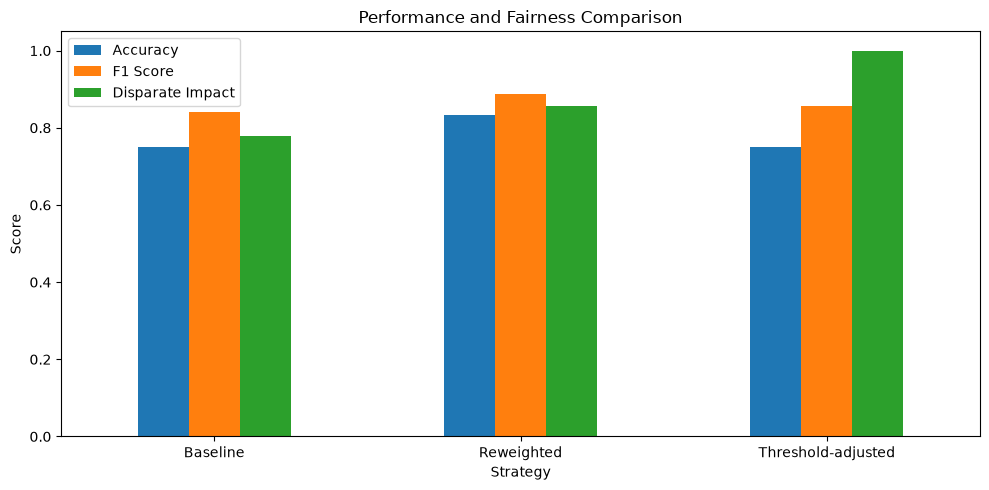

In [5]:
def fairness_summary(name, actual, predicted, group_metrics):
    positive_rates = group_metrics["Positive Rate"].dropna()
    tprs = group_metrics["TPR"].dropna()
    fprs = group_metrics["FPR"].dropna()

    return {
        "Strategy": name,
        "Accuracy": accuracy_score(actual, predicted),
        "F1 Score": f1_score(actual, predicted, zero_division=0),
        "Disparate Impact": (
            positive_rates.min() / positive_rates.max()
            if len(positive_rates) >= 2 and positive_rates.max() > 0
            else np.nan
        ),
        "TPR Gap": tprs.max() - tprs.min() if len(tprs) >= 2 else np.nan,
        "FPR Gap": fprs.max() - fprs.min() if len(fprs) >= 2 else np.nan
    }

summary = pd.DataFrame([
    fairness_summary("Baseline", y_test, base_pred, base_fairness),
    fairness_summary("Reweighted", y_test, rw_pred, rw_fairness),
    fairness_summary(
        "Threshold-adjusted", y_test, threshold_pred, threshold_fairness
    )
])

print(summary.round(4).to_string(index=False))

summary.set_index("Strategy")[["Accuracy", "F1 Score", "Disparate Impact"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Performance and Fairness Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()